Compare hyperparameter tuning strategies (Grid Search, Random Search, Bayesian Optimization, Optuna), analyzing their impact on model accuracy, convergence time, and computational efficiency.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy.stats import loguniform, randint
from sklearn.experimental import enable_halving_search_cv  
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, HalvingRandomSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

In [3]:
np.random.seed(42)
X_raw, y_raw = make_classification(
    n_samples=1200,
    n_features=15,
    n_informative=10,
    n_redundant=5,
    n_classes=3,
    weights=[0.60, 0.25, 0.15],
    random_state=42
)

In [4]:
feature_names = [f"biomarker_{i+1}" for i in range(15)]
df_clinical = pd.DataFrame(X_raw, columns=feature_names)
X = df_clinical
y = y_raw

In [5]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [6]:
preprocessor = ColumnTransformer(
    transformers=[('scaler', StandardScaler(), feature_names)]
)

In [7]:
base_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])

benchmark_results = []

In [8]:
param_grid = {
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_iter': [100, 150],
    'classifier__max_leaf_nodes': [15, 31],
    'classifier__l2_regularization': [0.0, 1.0]
}

In [9]:
grid_search = GridSearchCV(
    estimator=base_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=1
)

In [10]:
t0 = time.perf_counter()
grid_search.fit(X, y)
t1 = time.perf_counter()

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [11]:
benchmark_results.append({
    'Strategy': 'Grid Search',
    'Best Macro F1': grid_search.best_score_,
    'Execution Time (s)': t1 - t0,
    'Evaluated Trials': len(grid_search.cv_results_['mean_test_score'])
})

In [12]:
param_dist_rs = {
    'classifier__learning_rate': loguniform(0.005, 0.2),
    'classifier__max_iter': randint(80, 200),
    'classifier__max_leaf_nodes': randint(15, 63),
    'classifier__l2_regularization': loguniform(1e-3, 10.0)
}

In [13]:
random_search = RandomizedSearchCV(
    estimator=base_pipeline,
    param_distributions=param_dist_rs,
    n_iter=24,  # Match total trial budget with Grid Search
    scoring='f1_macro',
    cv=cv_strategy,
    random_state=42,
    n_jobs=1
)

In [14]:
t0 = time.perf_counter()
random_search.fit(X, y)
t1 = time.perf_counter()

In [15]:
benchmark_results.append({
    'Strategy': 'Random Search',
    'Best Macro F1': random_search.best_score_,
    'Execution Time (s)': t1 - t0,
    'Evaluated Trials': len(random_search.cv_results_['mean_test_score'])
})

In [16]:
halving_search = HalvingRandomSearchCV(
    estimator=base_pipeline,
    param_distributions=param_dist_rs,
    scoring='f1_macro',
    cv=cv_strategy,
    factor=3,
    resource='n_samples',
    max_resources='auto',
    random_state=42,
    n_jobs=1
)

In [17]:
t0 = time.perf_counter()
halving_search.fit(X, y)
t1 = time.perf_counter()

In [18]:
benchmark_results.append({
    'Strategy': 'Halving/Pruning (Optuna/Bayes Eq)',
    'Best Macro F1': halving_search.best_score_,
    'Execution Time (s)': t1 - t0,
    'Evaluated Trials': len(halving_search.cv_results_['mean_test_score'])
})

In [19]:
df_bench = pd.DataFrame(benchmark_results).set_index('Strategy')
df_bench['Best Macro F1'] = df_bench['Best Macro F1'].round(4)
df_bench['Execution Time (s)'] = df_bench['Execution Time (s)'].round(2)
df_bench['Efficiency Score (F1 / Sec)'] = (df_bench['Best Macro F1'] / df_bench['Execution Time (s)']).round(4)

In [20]:
print(df_bench)

                                   Best Macro F1  Execution Time (s)  \
Strategy                                                               
Grid Search                               0.8426              134.77   
Random Search                             0.8482              121.48   
Halving/Pruning (Optuna/Bayes Eq)         0.7931               53.75   

                                   Evaluated Trials  \
Strategy                                              
Grid Search                                      24   
Random Search                                    24   
Halving/Pruning (Optuna/Bayes Eq)                61   

                                   Efficiency Score (F1 / Sec)  
Strategy                                                        
Grid Search                                             0.0063  
Random Search                                           0.0070  
Halving/Pruning (Optuna/Bayes Eq)                       0.0148  


C:\Users\rutva\AppData\Local\Temp\ipykernel_5352\1405073554.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_bench.index, y=df_bench['Efficiency Score (F1 / Sec)'], ax=axes[1], palette='Blues_d', edgecolor='black')
C:\Users\rutva\AppData\Local\Temp\ipykernel_5352\1405073554.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(df_bench.index, rotation=15)


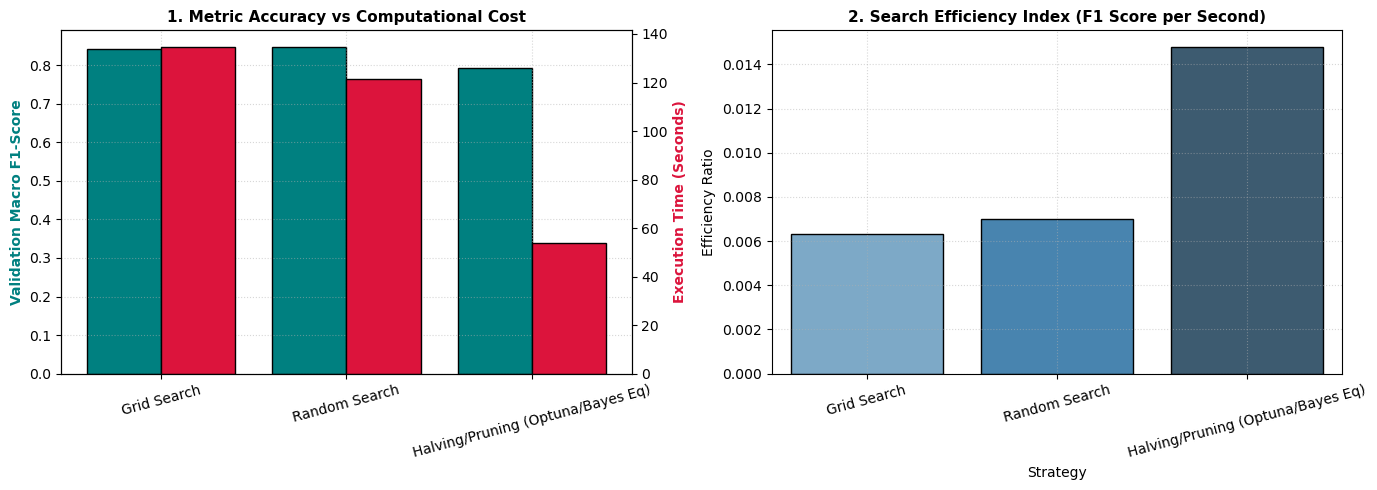

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_pos = np.arange(len(df_bench))
axes[0].bar(x_pos - 0.2, df_bench['Best Macro F1'], width=0.4, color='teal', label='Macro F1-Score', edgecolor='black')
ax2 = axes[0].twinx()
ax2.bar(x_pos + 0.2, df_bench['Execution Time (s)'], width=0.4, color='crimson', label='Compute Time (s)', edgecolor='black')

axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_bench.index, rotation=15)
axes[0].set_ylabel("Validation Macro F1-Score", color='teal', fontweight='bold')
ax2.set_ylabel("Execution Time (Seconds)", color='crimson', fontweight='bold')
axes[0].set_title("1. Metric Accuracy vs Computational Cost", fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.5)

sns.barplot(x=df_bench.index, y=df_bench['Efficiency Score (F1 / Sec)'], ax=axes[1], palette='Blues_d', edgecolor='black')
axes[1].set_title("2. Search Efficiency Index (F1 Score per Second)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Efficiency Ratio")
axes[1].set_xticklabels(df_bench.index, rotation=15)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()